In [1]:
# 1 — Imports and load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd

DATA_PATH = PROJECT_ROOT / "data" / "cleaned" / "adult_cleaned.csv"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, dtype={"zip_code": "string"})
df = df.dropna(subset=["income"]).copy()

df["income"] = df["income"].astype(str).str.strip()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (32561, 16)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,zip_code
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,93810
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,24592
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,13278
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,46048
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,42098


In [2]:
# 2 — Prepare features and split the data

TARGET = "income"

X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Training target distribution:")
display(y_train.value_counts(normalize=True).round(3))

Training set: (26048, 15)
Testing set: (6513, 15)
Training target distribution:


income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64

In [3]:
# 3 — Build the preprocessing pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [4]:
# 4 — Define the two baseline models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Models defined:", list(models.keys()))

Models defined: ['Logistic Regression', 'Random Forest']


In [5]:
# 5 — Train and evaluate both models

results = []
trained_pipelines = {}
predictions = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_pipelines[name] = pipeline
    predictions[name] = y_pred

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(
            y_test, y_pred, pos_label=">50K", zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, pos_label=">50K", zero_division=0
        ),
        "f1_score": f1_score(
            y_test, y_pred, pos_label=">50K", zero_division=0
        )
    })

metrics_df = pd.DataFrame(results)

display(metrics_df.round(4))

Training Logistic Regression...
Training Random Forest...


,model,accuracy,precision,recall,f1_score
0,Logistic Regression,0.8551,0.7404,0.6129,0.6706
1,Random Forest,0.8607,0.7707,0.6001,0.6748


In [6]:
# 6 — Classification reports

for name, y_pred in predictions.items():
    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)

    print(classification_report(
        y_test,
        y_pred,
        labels=["<=50K", ">50K"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4945
        >50K       0.74      0.61      0.67      1568

    accuracy                           0.86      6513
   macro avg       0.81      0.77      0.79      6513
weighted avg       0.85      0.86      0.85      6513


Random Forest
              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      4945
        >50K       0.77      0.60      0.67      1568

    accuracy                           0.86      6513
   macro avg       0.83      0.77      0.79      6513
weighted avg       0.85      0.86      0.85      6513



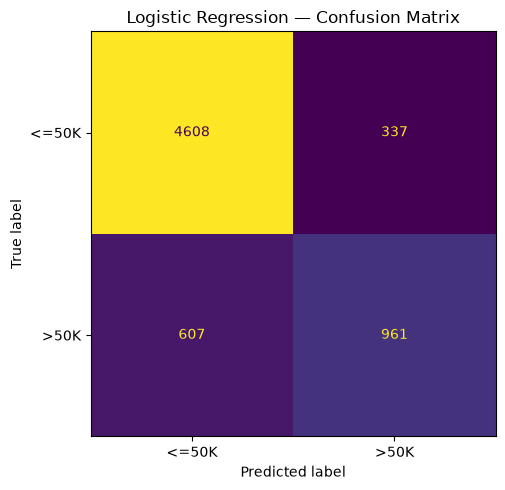

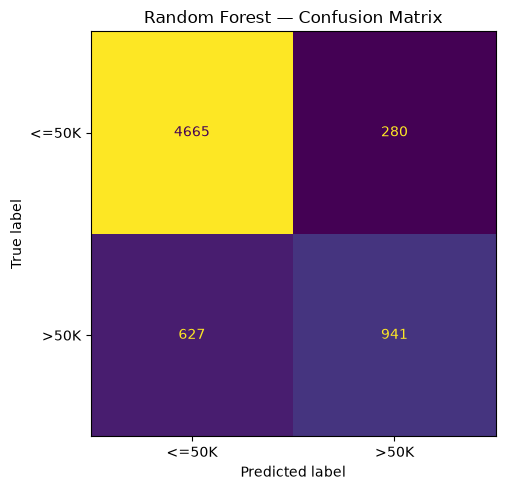

In [7]:
# 7 — Plot and save confusion matrices

for name, y_pred in predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["<=50K", ">50K"]
    )

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["<=50K", ">50K"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    display_plot.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"{name} — Confusion Matrix")
    fig.tight_layout()

    filename = name.lower().replace(" ", "_")
    fig.savefig(
        FIGURES_DIR / f"{filename}_confusion_matrix.png",
        dpi=150
    )
    plt.show()
    plt.close(fig)

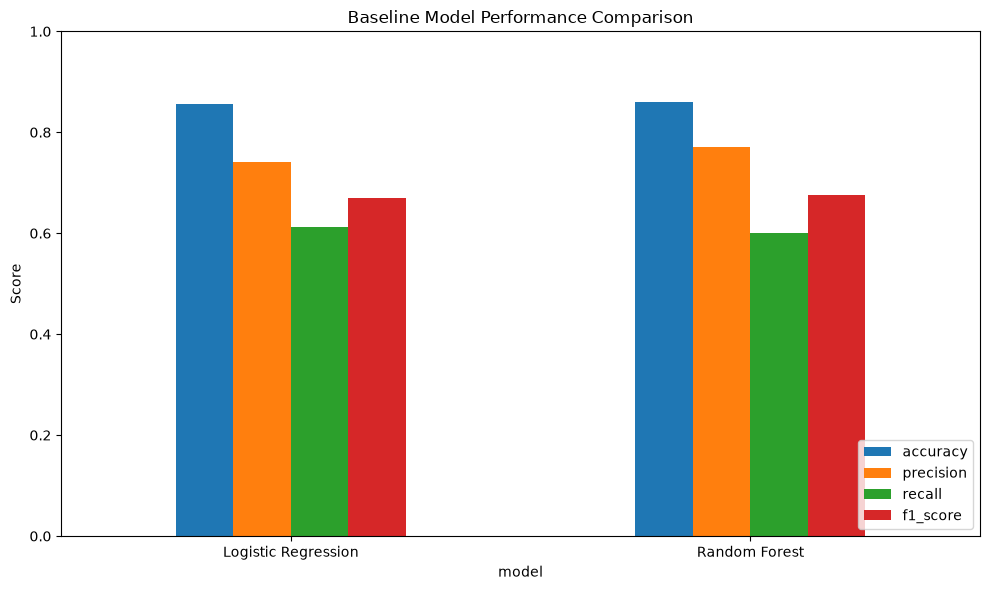

In [8]:
# 8 — Compare models visually

metrics_df.set_index("model")[
    ["accuracy", "precision", "recall", "f1_score"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "baseline_model_comparison.png",
    dpi=150
)
plt.show()

In [9]:
# 9 — Save the baseline metrics

metrics_path = RESULTS_DIR / "baseline_metrics.csv"

metrics_df.to_csv(metrics_path, index=False)

print("Metrics saved to:", metrics_path)
display(metrics_df.round(4))

Metrics saved to: d:\VS Code\Projects\python\Internship\results\baseline_metrics.csv


,model,accuracy,precision,recall,f1_score
0,Logistic Regression,0.8551,0.7404,0.6129,0.6706
1,Random Forest,0.8607,0.7707,0.6001,0.6748
